# Q2 — Context Invariance

**Research question:** Which PPC neurons maintain stable encoding profiles across visual and auditory decision contexts (context-invariant), and which are context-specific?

**Abstract claim:** *"Decision representations partially generalized across explicitly different sensory contexts, supported by a heterogeneous mixture of context-invariant and context-dependent neurons."*

**Analyses:**
- **Sec 0** — Setup & data loading
- **Sec 1** — Per-context model performance (FDE by context, context preference distributions)
- **Sec 2** — Context invariance proxy (using full-model FDE per context as proxy for encoding stability)
- **Sec 3** — CG-enhanced example neuron (visual validation of context modulation)
- **Sec 4** — Cross-modal stimulus coding (audio vs visual stim selectivity)
- **Sec 5** — Placeholder: per-context lesion analysis (requires `run_sessions_ctx_lesion.py`)

**Proxy approach:** Until per-context lesion results are available, context invariance is assessed using `frac_dev_visual` vs `frac_dev_audio` similarity. A neuron is *context-invariant* if `|vis_aud_CI| < threshold`, *visual-specific* if CI >> 0, *audio-specific* if CI << 0.

## Section 0 — Setup & Data Loading

In [1]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib import rcParams
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from scipy.stats import friedmanchisquare, wilcoxon
from scipy.stats import pearsonr
from itertools import combinations

GLM_DIR = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model'
if GLM_DIR not in sys.path:
    sys.path.insert(0, GLM_DIR)
from core.session_pipeline import BASE_DATA_PATH, MODEL_1_DIR, Y_SCALE, Y_SMOOTH_SIGMA

os.makedirs(os.path.join(GLM_DIR, 'figures'), exist_ok=True)

rcParams['font.family']       = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top']   = False
rcParams['axes.labelsize']    = 7
rcParams['xtick.labelsize']   = 7
rcParams['ytick.labelsize']   = 7
rcParams['figure.dpi']        = 800

CTX_COLORS_STR = {'cg': '#9B59B6', 'visual': '#EC008C', 'audio': '#27AAE1'}

M1_GROUPS = [
    'position_only',
    'audio_context', 'audio_stim',
    'visual_context', 'visual_stim',
    'velocity',
    'choice_spatial', 'turn_onset',
    'outcome',
]
GROUP_LABELS = {
    'position_only':  'Position',  'audio_context':  'Audio Ctx',
    'audio_stim':     'Audio Stim','visual_context': 'Visual Ctx',
    'visual_stim':    'Visual Stim','velocity':       'Velocity',
    'choice_spatial': 'Choice',    'turn_onset':     'Turn Onset',
    'outcome':        'Outcome',
}
GROUP_COLORS = {
    'position_only':  '#9B59B6', 'audio_context':  '#27AAE1',
    'audio_stim':     '#1A7AAF', 'visual_context': '#EC008C',
    'visual_stim':    '#A8005E', 'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22', 'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
}
CLASS_COLORS = {**GROUP_COLORS, 'mixed': '#95A5A6', 'unclassified': '#BDC3C7'}

RESP_THRESHOLD = 0.1
CTX_THRESHOLD  = 0.1   # per-context FDE threshold for 'responsive in context'
CI_THRESH      = 0.20  # |vis_aud_CI| threshold for invariant vs specific
print('Setup complete')

Setup complete


In [2]:
PPC_AVC = {
    'IS-2-1L': ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13',
                '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04',
                '2025-04-08', '2025-04-09', '2025-05-05',
                '2025-05-28', '2025-05-30', '2025-11-20'],
    'IS-3-1R': ['2024-12-23', '2024-12-24'],
    'JP-2-1L': ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17',
                '2025-09-19', '2025-09-22'],
    'KA-1-00': ['2025-12-16', '2026-01-08'],
    'KA-2-00': ['2026-01-08', '2026-01-13', '2026-01-14'],
    'KO-5-1L': ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13', '2026-03-24'],
    'KO-6-00': ['2026-03-12', '2026-03-23', '2026-03-25'],
}
total = sum(len(v) for v in PPC_AVC.values())
print(f'Registry: {len(PPC_AVC)} mice | {total} sessions')

Registry: 7 mice | 35 sessions


In [3]:
def load_sessions(sessions_dict, model_dir, prefix):
    sessions = []
    for mouse_ID, dates in sessions_dict.items():
        for date in dates:
            res_dir     = os.path.join(BASE_DATA_PATH, mouse_ID, date, model_dir)
            full_path   = os.path.join(res_dir, f'{prefix}_full.pkl')
            lesion_path = os.path.join(res_dir, f'{prefix}_lesion_all.pkl')
            if not os.path.exists(full_path):
                continue
            with open(full_path, 'rb') as f:
                full_res = pickle.load(f)
            lesion_res = None
            if os.path.exists(lesion_path):
                with open(lesion_path, 'rb') as f:
                    lesion_res = pickle.load(f)
            n = full_res['test_frac_dev'].shape[0]
            sessions.append(dict(mouse_ID=mouse_ID, date=date,
                                 full_res=full_res, lesion_res=lesion_res))
            tag = '+ lesion' if lesion_res else '  no lesion'
            print(f'  {mouse_ID}/{date}  n={n:5d}  {tag}')
    print(f'Loaded {len(sessions)} sessions')
    return sessions


def build_neuron_df(sessions, resp_threshold=0.1, mixed_margin=0.5):
    rows = []
    for s in sessions:
        mouse_ID, date = s['mouse_ID'], s['date']
        full_res, lesion_res = s['full_res'], s['lesion_res']
        n = len(full_res['test_frac_dev'])
        base = {
            'mouse_ID':        [mouse_ID]*n,
            'date':            [date]*n,
            'neuron_idx':      np.arange(n),
            'test_frac_dev':   full_res['test_frac_dev'],
            'cv_frac_dev':     full_res.get('cv_frac_dev', np.full(n, np.nan)),
            'frac_dev_cg':     full_res['test_frac_dev_per_ctx'].get(0, np.zeros(n)),
            'frac_dev_visual': full_res['test_frac_dev_per_ctx'].get(1, np.zeros(n)),
            'frac_dev_audio':  full_res['test_frac_dev_per_ctx'].get(2, np.zeros(n)),
        }
        df_s = pd.DataFrame(base)
        if lesion_res is not None:
            for grp in lesion_res['groups']:
                df_s[f'delta_fd_{grp}'] = lesion_res['delta_frac_dev'].get(grp, np.full(n, np.nan))
        rows.append(df_s)

    df = pd.concat(rows, ignore_index=True)
    df['neuron_uid'] = df['mouse_ID'] + '_' + df['date'] + '_n' + df['neuron_idx'].astype(str)
    df = df.set_index('neuron_uid')
    df['is_responsive'] = df['test_frac_dev'] > resp_threshold

    # Dominant group classification
    delta_cols = [c for c in df.columns if c.startswith('delta_fd_')]
    if delta_cols:
        dc = df[delta_cols].clip(lower=0)
        df['dominant_group'] = dc.idxmax(axis=1).str.replace('delta_fd_', '', regex=False)
        df['dominant_delta'] = dc.max(axis=1)
        _dc = dc.to_numpy().copy()
        _dc[np.arange(len(_dc)), dc.values.argmax(axis=1)] = 0.0
        df['runner_up_group'] = (
            pd.Series(np.array(delta_cols)[_dc.argmax(axis=1)], index=df.index)
            .str.replace('delta_fd_', '', regex=False)
        )
        df['runner_up_delta'] = _dc.max(axis=1)
        with np.errstate(divide='ignore', invalid='ignore'):
            df['mixedness'] = np.where(df['dominant_delta'] > 0,
                                       df['runner_up_delta'] / df['dominant_delta'], 0.0)
        df['is_mixed'] = df['mixedness'] >= mixed_margin
        df['neuron_class'] = np.where(
            ~df['is_responsive'] | (df['dominant_delta'] <= 0), 'unclassified',
            np.where(df['is_mixed'], 'mixed', df['dominant_group'])
        )

    # Context-preference metrics
    df['cg_advantage'] = (
        df['frac_dev_cg'] - df[['frac_dev_visual', 'frac_dev_audio']].max(axis=1)
    )
    # Visual-Audio context index: +1 = pure visual, -1 = pure audio, 0 = equal
    denom = df['frac_dev_visual'] + df['frac_dev_audio'] + 1e-8
    df['vis_aud_ci'] = (df['frac_dev_visual'] - df['frac_dev_audio']) / denom

    # Per-context responsiveness
    df['resp_visual'] = df['frac_dev_visual'] > resp_threshold
    df['resp_audio']  = df['frac_dev_audio']  > resp_threshold
    df['resp_cg']     = df['frac_dev_cg']     > resp_threshold

    n_resp = df['is_responsive'].sum()
    print(f'{len(df):,} neurons total | {n_resp:,} responsive ({n_resp/len(df)*100:.1f}%)')
    return df


print('Loaders defined')

Loaders defined


In [4]:
print('Loading Model 1...')
sessions_m1 = load_sessions(PPC_AVC, model_dir='Model_1_results', prefix='glm_M1')
df_m1   = build_neuron_df(sessions_m1)
resp_m1 = df_m1['is_responsive']
df_resp = df_m1[resp_m1].copy()
print(f'\nResponsive neurons: {resp_m1.sum():,}')

Loading Model 1...
  IS-2-1L/2025-03-10  n= 2115  + lesion
  IS-2-1L/2025-03-11  n= 1958  + lesion
  IS-2-1L/2025-03-12  n= 1783  + lesion
  IS-2-1L/2025-03-13  n= 1143    no lesion
  IS-2-1L/2025-03-20  n= 1800  + lesion
  IS-2-1L/2025-03-26  n= 1757  + lesion
  IS-2-1L/2025-04-02  n= 1884  + lesion
  IS-2-1L/2025-04-04  n= 2019  + lesion
  IS-2-1L/2025-04-08  n= 2049  + lesion
  IS-2-1L/2025-04-09  n= 1598  + lesion
  IS-2-1L/2025-05-05  n= 2147  + lesion
  IS-2-1L/2025-05-28  n= 1451  + lesion
  IS-2-1L/2025-05-30  n= 1122  + lesion
  IS-2-1L/2025-11-20  n= 1874  + lesion
  IS-3-1R/2024-12-23  n= 1855  + lesion
  IS-3-1R/2024-12-24  n= 2139  + lesion
  JP-2-1L/2025-08-19  n= 2325  + lesion
  JP-2-1L/2025-08-26  n= 1830  + lesion
  JP-2-1L/2025-09-16  n= 1654  + lesion
  JP-2-1L/2025-09-17  n= 1135  + lesion
  JP-2-1L/2025-09-19  n= 1566  + lesion
  JP-2-1L/2025-09-22  n= 1835  + lesion
  KA-1-00/2025-12-16  n= 1274  + lesion
  KA-1-00/2026-01-08  n= 1555  + lesion
  KA-2-00/2026-01-

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_80727/3821186666.py:56: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  df['dominant_group'] = dc.idxmax(axis=1).str.replace('delta_fd_', '', regex=False)


## Section 1 — Per-Context Model Performance

How well does the model explain variance in each sensory context?

- **1a** Bar plot: mean session-median FDE per context ± SEM, with Friedman test
- **1b** CDF per context
- **1c** Context preference distribution (which context is each neuron best-fit?)

Friedman test (N=35 sessions): chi2=16.63  p=2.45e-04
  Visual vs Audio: W=238.0  p=2.131e-01  p_bonf=6.392e-01
  Visual vs CG: W=156.0  p=8.235e-03  p_bonf=2.470e-02
  Audio vs CG: W=117.0  p=7.825e-04  p_bonf=2.348e-03


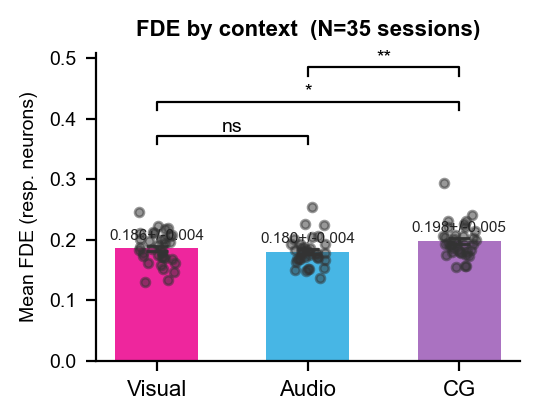

In [5]:
# ── 1a. FDE by context — bar plot with session-level statistics ──────────
def plot_fde_by_context(df, resp_threshold=RESP_THRESHOLD, figsize=(2.8, 2.2)):
    resp_df    = df[df['test_frac_dev'] > resp_threshold]
    ctx_cols   = ['frac_dev_visual', 'frac_dev_audio', 'frac_dev_cg']
    ctx_labels = ['Visual', 'Audio', 'CG']
    ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio'], CTX_COLORS_STR['cg']]

    sess_ctx = (
        resp_df.groupby(['mouse_ID', 'date'])[ctx_cols]
        .median().reset_index()
    )
    n_sess = len(sess_ctx)

    # Friedman test across sessions
    stat, p_fr = friedmanchisquare(*[sess_ctx[c].values for c in ctx_cols])
    print(f'Friedman test (N={n_sess} sessions): chi2={stat:.2f}  p={p_fr:.2e}')

    pairs = list(combinations(range(3), 2))
    pw_results = []
    for i, j in pairs:
        w_stat, p_w = wilcoxon(sess_ctx[ctx_cols[i]], sess_ctx[ctx_cols[j]])
        p_corr = min(p_w * len(pairs), 1.0)
        pw_results.append((i, j, p_w, p_corr))
        print(f'  {ctx_labels[i]} vs {ctx_labels[j]}: '
              f'W={w_stat:.1f}  p={p_w:.3e}  p_bonf={p_corr:.3e}')

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    for i, (col, color) in enumerate(zip(ctx_cols, ctx_colors)):
        mean_val = sess_ctx[col].mean()
        sem_val  = sess_ctx[col].sem()
        ax.bar(i, mean_val, yerr=sem_val, width=0.55, color=color, alpha=0.85,
               error_kw=dict(elinewidth=1.2, capsize=4, ecolor='#333333'), zorder=2)
        rng     = np.random.default_rng(seed=i)
        jitter  = rng.uniform(-0.12, 0.12, size=n_sess)
        ax.scatter(i + jitter, sess_ctx[col].values,
                   color='#333333', s=10, alpha=0.5, zorder=3)
        ax.text(i, mean_val + sem_val + 0.005,
                f'{mean_val:.3f}+/-{sem_val:.3f}',
                ha='center', va='bottom', fontsize=5.5, color='#222222')

    def sig_label(p):
        if p < 0.001: return '***'
        if p < 0.01:  return '**'
        if p < 0.05:  return '*'
        return 'ns'

    y_top     = max(sess_ctx[c].max() for c in ctx_cols)
    y_step    = y_top * 0.12
    bracket_y = y_top + y_step * 1.8
    for (i, j, p_raw, p_corr) in pw_results:
        bar_h = bracket_y + y_step * 0.4
        ax.plot([i, i, j, j], [bracket_y, bar_h, bar_h, bracket_y], lw=0.8, color='k')
        ax.text((i + j) / 2, bar_h, sig_label(p_corr),
                ha='center', va='bottom', fontsize=7)
        bracket_y += y_step * 1.6

    ax.set_xticks(range(3))
    ax.set_xticklabels(ctx_labels, fontsize=8)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)
    ax.set_title(f'FDE by context  (N={n_sess} sessions)', fontsize=8, fontweight='bold')
    sns.despine()
    plt.tight_layout()
    return fig

fig = plot_fde_by_context(df_m1)
plt.savefig('figures/Q2_fde_by_context.svg', bbox_inches='tight', facecolor='white')
plt.show()

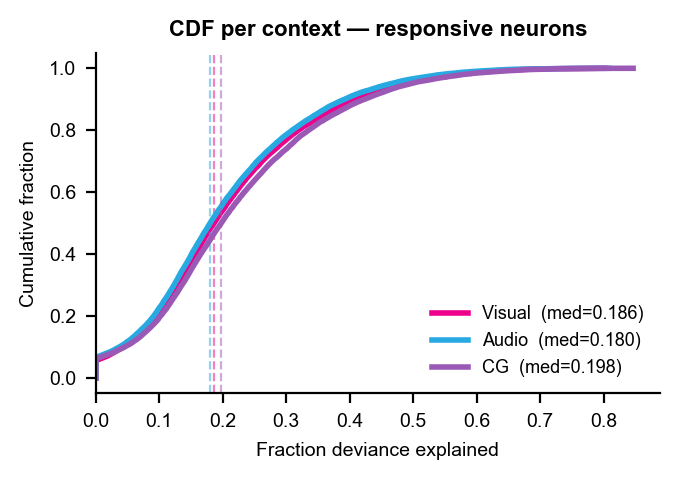

In [6]:
# ── 1b. CDF per context ──────────────────────────────────────────────────
ctx_cols   = ['frac_dev_visual', 'frac_dev_audio', 'frac_dev_cg']
ctx_labels = ['Visual', 'Audio', 'CG']
ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio'], CTX_COLORS_STR['cg']]

fig, ax = plt.subplots(figsize=(3.5, 2.5), dpi=200)
for col, lbl, color in zip(ctx_cols, ctx_labels, ctx_colors):
    x = np.sort(df_resp[col].values)
    y = np.linspace(0, 1, len(x))
    ax.plot(x, y, color=color, lw=2, label=f'{lbl}  (med={np.median(x):.3f})')
    ax.axvline(np.median(x), color=color, lw=0.8, ls='--', alpha=0.5)

ax.set_xlabel('Fraction deviance explained', fontsize=7)
ax.set_ylabel('Cumulative fraction', fontsize=7)
ax.set_title('CDF per context — responsive neurons', fontsize=8, fontweight='bold')
ax.set_xlim(0, None)
ax.legend(fontsize=6.5, frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig('figures/Q2_cdf_by_context.svg', bbox_inches='tight', facecolor='white')
plt.show()

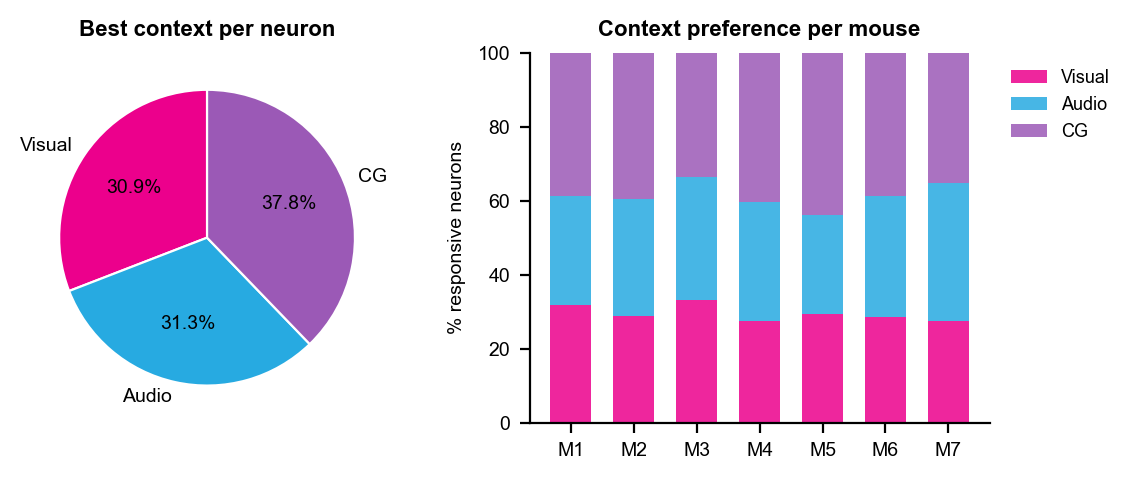

In [7]:
# ── 1c. Context preference distribution ──────────────────────────────────
# Best-context for each neuron
ctx_map = {'frac_dev_visual': 'Visual', 'frac_dev_audio': 'Audio', 'frac_dev_cg': 'CG'}
df_resp['best_context'] = df_resp[ctx_cols].idxmax(axis=1).map(ctx_map)

fig, axes = plt.subplots(1, 2, figsize=(6, 2.5), dpi=200)

# Donut: overall
ax = axes[0]
order  = ['Visual', 'Audio', 'CG']
counts = df_resp['best_context'].value_counts()
vals   = [counts.get(c, 0) for c in order]
colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio'], CTX_COLORS_STR['cg']]
ax.pie(vals, labels=order, colors=colors,
       autopct='%1.1f%%', startangle=90,
       textprops={'fontsize': 7},
       wedgeprops={'linewidth': 0.8, 'edgecolor': 'white'})
ax.set_title('Best context per neuron', fontsize=8, fontweight='bold')

# Stacked bar: per mouse
ax = axes[1]
mice   = sorted(df_resp['mouse_ID'].unique())
mlabels = [f'M{i+1}' for i in range(len(mice))]
bottom  = np.zeros(len(mice))
for ctx, color in zip(order, colors):
    fracs = [
        (df_resp[df_resp['mouse_ID'] == m]['best_context'] == ctx).mean() * 100
        for m in mice
    ]
    ax.bar(mlabels, fracs, bottom=bottom, color=color, label=ctx, width=0.65, alpha=0.85)
    bottom += np.array(fracs)
ax.set_ylabel('% responsive neurons', fontsize=7)
ax.set_title('Context preference per mouse', fontsize=8, fontweight='bold')
ax.set_ylim(0, 100)
ax.legend(fontsize=6.5, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig('figures/Q2_context_preference.svg', bbox_inches='tight', facecolor='white')
plt.show()

## Section 2 — Context Invariance Proxy Analysis

Using full-model FDE per context as a proxy for encoding stability across contexts.

**Visual-Audio Context Index (vis_aud_CI):** `(FDE_vis - FDE_aud) / (FDE_vis + FDE_aud)`
- CI ~ 0 → context-invariant (equal encoding in both unimodal contexts)
- CI >> 0 → visual-specific
- CI << 0 → audio-specific

**Classification threshold:** `|CI| < {CI_THRESH}` = invariant; `CI > {CI_THRESH}` = visual-specific; `CI < -{CI_THRESH}` = audio-specific.

> **Limitation:** This proxy cannot distinguish whether a neuron's *encoding profile* (which behavioral variable it encodes) changes across contexts, only whether the overall model fit changes. Per-context lesion analysis (Sec 5) is needed for the full picture.

In [8]:
# ── 2a. Classify neurons by context invariance ───────────────────────────
def classify_context_invariance(df, ci_thresh=CI_THRESH, ctx_thresh=CTX_THRESHOLD):
    """Classify each responsive neuron as invariant / visual-specific / audio-specific."""
    df = df.copy()

    # Only neurons responsive in at least one unimodal context
    resp_either = (df['frac_dev_visual'] > ctx_thresh) | (df['frac_dev_audio'] > ctx_thresh)

    conditions = [
        (~resp_either),
        resp_either & (df['vis_aud_ci'].abs() < ci_thresh),
        resp_either & (df['vis_aud_ci'] >  ci_thresh),
        resp_either & (df['vis_aud_ci'] < -ci_thresh),
    ]
    choices = ['not_unimodal', 'invariant', 'visual_specific', 'audio_specific']
    df['ctx_invariance'] = np.select(conditions, choices, default='invariant')

    # Also flag CG-enhanced
    df['cg_enhanced'] = df['cg_advantage'] > 0

    return df


df_resp = classify_context_invariance(df_resp)

print('Context invariance classification (responsive neurons):')
print(df_resp['ctx_invariance'].value_counts())
print()
inv_counts = df_resp['ctx_invariance'].value_counts()
total_resp  = len(df_resp)
for label in ['invariant', 'visual_specific', 'audio_specific', 'not_unimodal']:
    n = inv_counts.get(label, 0)
    print(f'  {label:<20s}: {n:6,}  ({n/total_resp*100:.1f}%)')
print(f'  {"CG-enhanced":<20s}: {df_resp["cg_enhanced"].sum():6,}'
      f'  ({df_resp["cg_enhanced"].mean()*100:.1f}%)')

Context invariance classification (responsive neurons):
ctx_invariance
invariant          11529
visual_specific     7038
audio_specific      6278
not_unimodal        1192
Name: count, dtype: int64

  invariant           : 11,529  (44.3%)
  visual_specific     :  7,038  (27.0%)
  audio_specific      :  6,278  (24.1%)
  not_unimodal        :  1,192  (4.6%)
  CG-enhanced         :  9,838  (37.8%)


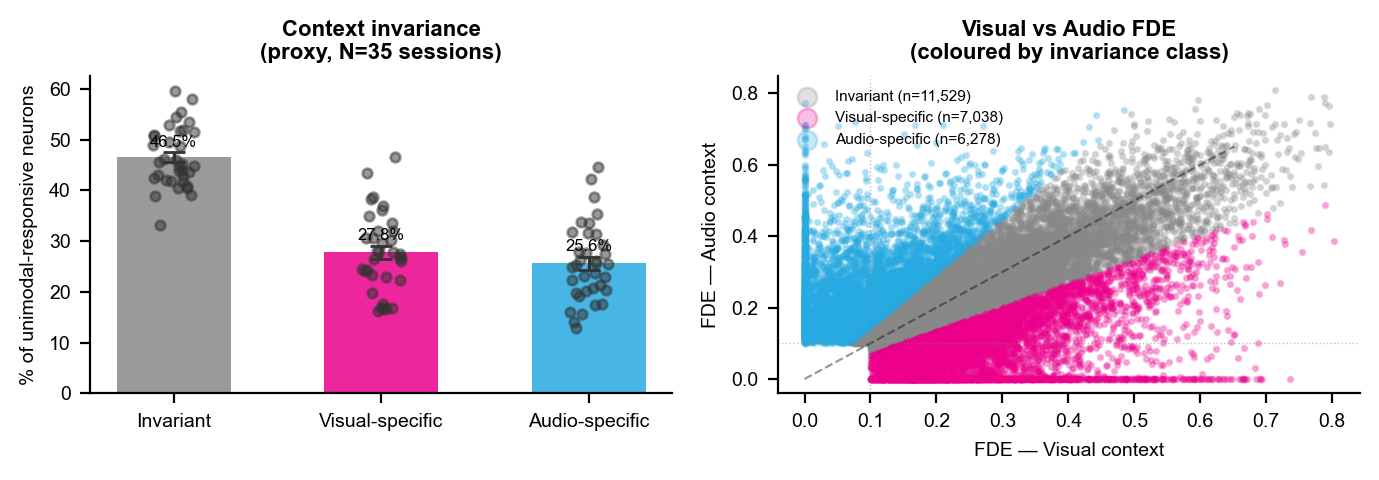

In [9]:
# ── 2b. Per-session % in each class ──────────────────────────────────────
inv_classes = ['invariant', 'visual_specific', 'audio_specific']
inv_colors  = ['#888888', CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio']]
inv_labels  = ['Invariant', 'Visual-specific', 'Audio-specific']

sess_inv = (
    df_resp[df_resp['ctx_invariance'] != 'not_unimodal']
    .groupby(['mouse_ID', 'date'])['ctx_invariance']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .reindex(columns=inv_classes, fill_value=0) * 100
)
sess_inv = sess_inv.reset_index()
n_sess = len(sess_inv)

fig, axes = plt.subplots(1, 2, figsize=(7, 2.5), dpi=200)

# Bar: grand mean ± SEM per class
ax = axes[0]
for i, (cls, color, lbl) in enumerate(zip(inv_classes, inv_colors, inv_labels)):
    mean_v = sess_inv[cls].mean()
    sem_v  = sess_inv[cls].sem()
    ax.bar(i, mean_v, yerr=sem_v, width=0.55, color=color, alpha=0.85,
           error_kw=dict(elinewidth=1.2, capsize=4, ecolor='#333333'))
    rng    = np.random.default_rng(seed=i)
    jitter = rng.uniform(-0.1, 0.1, size=n_sess)
    ax.scatter(i + jitter, sess_inv[cls].values,
               color='#333333', s=12, alpha=0.5, zorder=3)
    ax.text(i, mean_v + sem_v + 0.5, f'{mean_v:.1f}%',
            ha='center', va='bottom', fontsize=6)
ax.set_xticks(range(3))
ax.set_xticklabels(inv_labels, fontsize=7)
ax.set_ylabel('% of unimodal-responsive neurons', fontsize=7)
ax.set_title(f'Context invariance\n(proxy, N={n_sess} sessions)', fontsize=8, fontweight='bold')
sns.despine(ax=ax)

# Scatter: FDE_visual vs FDE_audio, coloured by class
ax = axes[1]
class_plot = [
    ('invariant',       '#888888', 'Invariant'),
    ('visual_specific', CTX_COLORS_STR['visual'], 'Visual-specific'),
    ('audio_specific',  CTX_COLORS_STR['audio'],  'Audio-specific'),
]
for cls, color, lbl in class_plot:
    sub = df_resp[df_resp['ctx_invariance'] == cls]
    if len(sub) == 0: continue
    ax.scatter(sub['frac_dev_visual'], sub['frac_dev_audio'],
               s=3, alpha=0.25, color=color, label=f'{lbl} (n={len(sub):,})')
lim = max(df_resp['frac_dev_visual'].quantile(0.99),
          df_resp['frac_dev_audio'].quantile(0.99)) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=0.8, alpha=0.4)
ax.axvline(CTX_THRESHOLD, color='gray', lw=0.5, ls=':', alpha=0.5)
ax.axhline(CTX_THRESHOLD, color='gray', lw=0.5, ls=':', alpha=0.5)
ax.set_xlabel('FDE — Visual context', fontsize=7)
ax.set_ylabel('FDE — Audio context', fontsize=7)
ax.set_title('Visual vs Audio FDE\n(coloured by invariance class)', fontsize=8, fontweight='bold')
ax.legend(fontsize=5.5, markerscale=4, frameon=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig('figures/Q2_context_invariance_proxy.svg', bbox_inches='tight', facecolor='white')
plt.show()

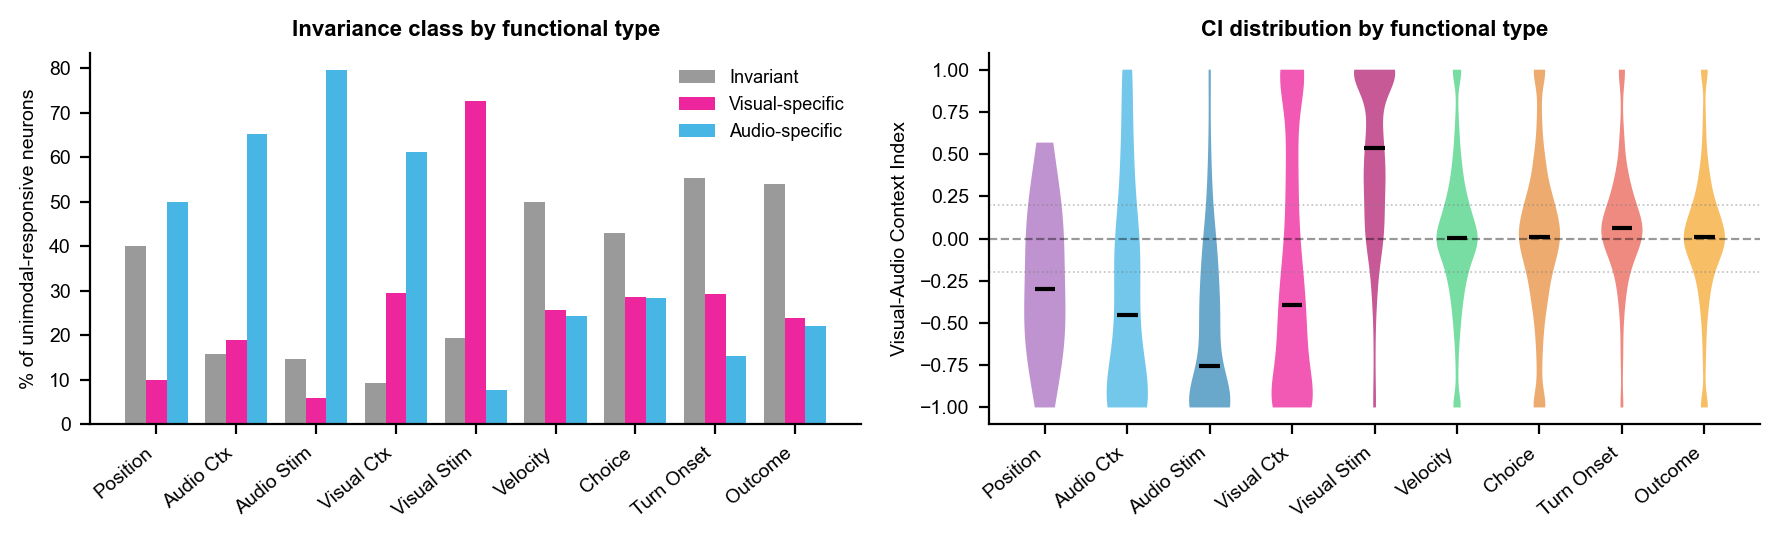

In [10]:
# ── 2c. Context invariance by functional type ────────────────────────────
if 'neuron_class' not in df_resp.columns:
    print('Skipping — lesion data required for neuron_class column.')
else:
    classes_present = [
        g for g in M1_GROUPS
        if g in df_resp['dominant_group'].values
    ]

    fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), dpi=200)

    # Bar: % invariant per functional type
    ax = axes[0]
    pct_inv  = []
    pct_vis  = []
    pct_aud  = []
    for g in classes_present:
        sub = df_resp[
            (df_resp['dominant_group'] == g) &
            (df_resp['ctx_invariance'] != 'not_unimodal')
        ]
        if len(sub) == 0:
            pct_inv.append(0); pct_vis.append(0); pct_aud.append(0)
            continue
        pct_inv.append((sub['ctx_invariance'] == 'invariant').mean()       * 100)
        pct_vis.append((sub['ctx_invariance'] == 'visual_specific').mean() * 100)
        pct_aud.append((sub['ctx_invariance'] == 'audio_specific').mean()  * 100)

    x = np.arange(len(classes_present))
    w = 0.26
    ax.bar(x - w, pct_inv, width=w, color='#888888', label='Invariant', alpha=0.85)
    ax.bar(x,     pct_vis, width=w, color=CTX_COLORS_STR['visual'],
           label='Visual-specific', alpha=0.85)
    ax.bar(x + w, pct_aud, width=w, color=CTX_COLORS_STR['audio'],
           label='Audio-specific', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in classes_present],
                       rotation=40, ha='right', fontsize=7)
    ax.set_ylabel('% of unimodal-responsive neurons', fontsize=7)
    ax.set_title('Invariance class by functional type', fontsize=8, fontweight='bold')
    ax.legend(fontsize=6.5, frameon=False)
    sns.despine(ax=ax)

    # Vis-aud CI distribution by type — violin
    ax = axes[1]
    data_ci = [
        df_resp[df_resp['dominant_group'] == g]['vis_aud_ci'].values
        for g in classes_present
    ]
    parts = ax.violinplot(data_ci, positions=range(len(classes_present)),
                          showmedians=True, showextrema=False)
    for pc, g in zip(parts['bodies'], classes_present):
        pc.set_facecolor(GROUP_COLORS.get(g, 'gray'))
        pc.set_alpha(0.65)
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(1.5)
    ax.axhline(0,   color='k',    lw=0.8, ls='--', alpha=0.4)
    ax.axhline( CI_THRESH, color='gray', lw=0.6, ls=':', alpha=0.5)
    ax.axhline(-CI_THRESH, color='gray', lw=0.6, ls=':', alpha=0.5)
    ax.set_xticks(range(len(classes_present)))
    ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in classes_present],
                       rotation=40, ha='right', fontsize=7)
    ax.set_ylabel('Visual-Audio Context Index', fontsize=7)
    ax.set_title('CI distribution by functional type', fontsize=8, fontweight='bold')
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q2_invariance_by_type.svg', bbox_inches='tight', facecolor='white')
    plt.show()

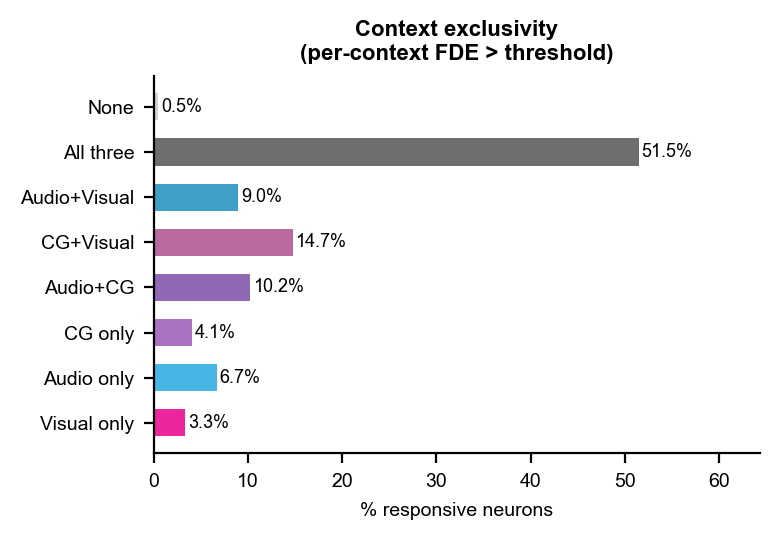


Context exclusivity summary:
  Visual only         :    870  (3.3%)
  Audio only          :  1,741  (6.7%)
  CG only             :  1,066  (4.1%)
  Audio+CG            :  2,662  (10.2%)
  CG+Visual           :  3,838  (14.7%)
  Audio+Visual        :  2,331  (9.0%)
  All three           : 13,403  (51.5%)
  None                :    126  (0.5%)


In [11]:
# ── 2d. Context exclusivity — what fraction respond in only one context? ──
def get_ctx_exclusivity(df):
    def label(row):
        active = [k for k, col in [('Visual', 'resp_visual'),
                                    ('Audio',  'resp_audio'),
                                    ('CG',     'resp_cg')] if row[col]]
        n = len(active)
        if n == 0: return 'None'
        if n == 3: return 'All three'
        if n == 1: return active[0] + ' only'
        return '+'.join(sorted(active))
    return df.apply(label, axis=1)

df_resp['ctx_exclusivity'] = get_ctx_exclusivity(df_resp)

order = ['Visual only', 'Audio only', 'CG only',
         'Audio+CG', 'CG+Visual', 'Audio+Visual', 'All three', 'None']
colors_map = {
    'Visual only':  CTX_COLORS_STR['visual'],
    'Audio only':   CTX_COLORS_STR['audio'],
    'CG only':      CTX_COLORS_STR['cg'],
    'Audio+CG':     '#7B4FA6',
    'CG+Visual':    '#B05090',
    'Audio+Visual': '#1E8EBF',
    'All three':    '#555555',
    'None':         '#CCCCCC',
}

counts = df_resp['ctx_exclusivity'].value_counts()
total  = len(df_resp)
present = [o for o in order if o in counts.index]
vals    = [counts[o] / total * 100 for o in present]
clrs    = [colors_map[o] for o in present]

fig, ax = plt.subplots(figsize=(4, 2.8), dpi=200)
bars = ax.barh(present, vals, color=clrs, alpha=0.85, height=0.6)
for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{v:.1f}%', va='center', fontsize=6.5)
ax.set_xlabel('% responsive neurons', fontsize=7)
ax.set_title('Context exclusivity\n(per-context FDE > threshold)', fontsize=8, fontweight='bold')
ax.set_xlim(0, max(vals) * 1.25)
sns.despine()
plt.tight_layout()
plt.savefig('figures/Q2_context_exclusivity.svg', bbox_inches='tight', facecolor='white')
plt.show()

print('\nContext exclusivity summary:')
for lbl in present:
    n = counts.get(lbl, 0)
    print(f'  {lbl:<20s}: {n:6,}  ({n/total*100:.1f}%)')

## Section 3 — CG-Enhanced Example Neuron

Visual validation: find a neuron whose model fit is substantially better during CG than in either unimodal context, and show the observed vs predicted traces for each context.

This provides an intuitive demonstration of context-dependent gain modulation.

In [12]:
from core.glm_class import make_prediction
from core.session_pipeline import add_coupling_predictor

CTX_MAP   = {0: 'CG', 1: 'Visual', 2: 'Audio'}
CTX_ORDER = [1, 2, 0]    # Visual | Audio | CG
WINDOW    = 800
STRIDE    = 20
FS        = 15.0

# ── Manual window overrides (set to None for auto-search) ────────────────
# Override per context if the auto-search picks a poor window.
T_STARTS = {1: None, 2: None, 0: None}   # {ctx_id: start_frame or None}

# ── Selection criteria ────────────────────────────────────────────────────
MIN_UNI_FDE = 0.15   # both visual and audio FDE must exceed this
MIN_CG_FDE  = 0.35   # CG FDE must exceed this

cg_df = df_m1[df_m1['test_frac_dev'] > 0.2].copy()
cg_df = cg_df[
    (cg_df['frac_dev_visual'] >= MIN_UNI_FDE) &
    (cg_df['frac_dev_audio']  >= MIN_UNI_FDE) &
    (cg_df['frac_dev_cg']     >= MIN_CG_FDE)
].copy()

if cg_df.empty:
    raise ValueError('No neurons meet criteria — try lowering MIN_UNI_FDE or MIN_CG_FDE')

cg_df['cg_advantage'] = cg_df['frac_dev_cg'] - np.maximum(
    cg_df['frac_dev_visual'], cg_df['frac_dev_audio']
)
best = cg_df.sort_values('cg_advantage', ascending=False).iloc[0]

ex_mouse = best['mouse_ID']
ex_date  = best['date']
nidx     = int(best['neuron_idx'])

print(f'Session     : {ex_mouse} / {ex_date}')
print(f'Neuron      : {nidx}')
print(f'FDE overall : {best["test_frac_dev"]:.3f}')
print(f'FDE Visual  : {best["frac_dev_visual"]:.3f}')
print(f'FDE Audio   : {best["frac_dev_audio"]:.3f}')
print(f'FDE CG      : {best["frac_dev_cg"]:.3f}')
print(f'CG advantage: {best["cg_advantage"]:.3f}')
print(f'Candidates  : {len(cg_df)}')

Session     : KO-5-1L / 2026-03-24
Neuron      : 1323
FDE overall : 0.330
FDE Visual  : 0.179
FDE Audio   : 0.173
FDE CG      : 0.574
CG advantage: 0.396
Candidates  : 3690


In [13]:
# ── Load data and compute predictions ────────────────────────────────────
ex_session = next(
    s for s in sessions_m1
    if s['mouse_ID'] == ex_mouse and s['date'] == ex_date
)
full_res = ex_session['full_res']

stacked_path = os.path.join(BASE_DATA_PATH, ex_mouse, ex_date, 'glm_data_stacked.pkl')
with open(stacked_path, 'rb') as f:
    glm_data = pickle.load(f)

X = glm_data['X']
Y = glm_data['Y'] * Y_SCALE
if Y_SMOOTH_SIGMA > 0:
    Y = gaussian_filter1d(Y, sigma=Y_SMOOTH_SIGMA, axis=0)
    Y = np.clip(Y, 0.0, None)

W  = full_res['weights']
w0 = full_res['w0'].flatten()
if W.shape[0] > X.shape[1]:   # model was fit with coupling predictors
    X, _, _ = add_coupling_predictor(
        X, Y, glm_data['predictor_info'], n_pcs=5, n_lag_bases=4, lag_frames=8
    )
    print(f'Coupling added: X -> {X.shape}')

metadata    = glm_data['metadata']
Y_pred_full = make_prediction(X, W, w0, activation='exp')
test_mask   = full_res['combined_test_mask']
print(f'Y_pred shape: {Y_pred_full.shape}')


  [Coupling] PCA on Y (1383 neurons):
    PC1: 2.8% variance explained
    PC2: 2.0% variance explained
    PC3: 1.8% variance explained
    PC4: 1.6% variance explained
    PC5: 1.5% variance explained
    Total: 9.7%
  [Coupling] Added 5 PCs × 4 lag bases = 20 columns  (X: 150 → 170)

Coupling added: X -> (63211, 170)
Y_pred shape: (63211, 1383)


In [14]:
# ── Find best window per context ─────────────────────────────────────────
def find_best_ctx_window(y_obs, y_pred, ctx_frames, window=WINDOW,
                          stride=STRIDE, min_mean=0.1):
    idx     = np.sort(ctx_frames)
    n       = len(idx)
    best_r  = -np.inf
    best_t0 = idx[0] if len(idx) > 0 else 0
    for k in range(0, n - window, stride):
        win_idx = idx[k:k + window]
        if win_idx[-1] - win_idx[0] > window * 3:
            continue
        yo = y_obs[win_idx]
        yp = y_pred[win_idx]
        if yo.mean() < min_mean or yo.std() < 1e-6 or yp.std() < 1e-6:
            continue
        r, _ = pearsonr(yo, yp)
        if r > best_r:
            best_r, best_t0 = r, win_idx[0]
    return best_t0, best_r


ctx_windows = {}
for ctx_id in CTX_ORDER:
    if T_STARTS[ctx_id] is not None:
        ctx_windows[ctx_id] = (T_STARTS[ctx_id], None)
        print(f'  {CTX_MAP[ctx_id]:6s}  manual  start={T_STARTS[ctx_id]}')
    else:
        ctx_frames = np.where(test_mask & (metadata['context'] == ctx_id))[0]
        if len(ctx_frames) < WINDOW:
            print(f'  {CTX_MAP[ctx_id]:6s}  SKIPPED — not enough test frames')
            ctx_windows[ctx_id] = (0, None)
            continue
        t0, r = find_best_ctx_window(Y[:, nidx], Y_pred_full[:, nidx], ctx_frames)
        ctx_windows[ctx_id] = (t0, r)
        print(f'  {CTX_MAP[ctx_id]:6s}  auto    start={t0}  r={r:.3f}')

  Visual  auto    start=23783  r=-inf
  Audio   auto    start=196  r=-inf
  CG      auto    start=12583  r=-inf


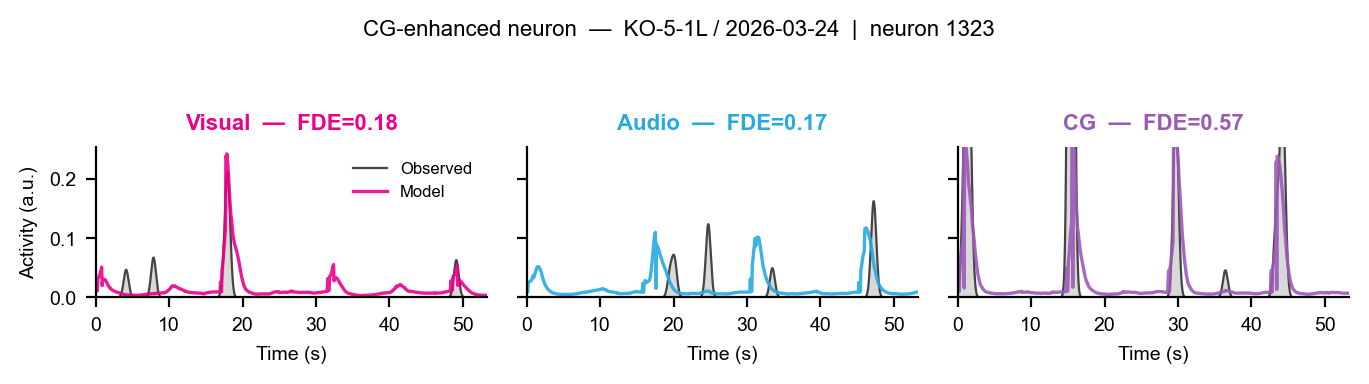

In [15]:
# ── Plot per-context traces ───────────────────────────────────────────────
fde_per_ctx = {
    0: float(best['frac_dev_cg']),
    1: float(best['frac_dev_visual']),
    2: float(best['frac_dev_audio']),
}
ctx_line_colors = {
    0: CTX_COLORS_STR['cg'],
    1: CTX_COLORS_STR['visual'],
    2: CTX_COLORS_STR['audio'],
}
t_axis = np.arange(WINDOW) / FS

fig, axes = plt.subplots(1, 3, figsize=(7, 1.8), dpi=200, sharey=True)

for col_i, ctx_id in enumerate(CTX_ORDER):
    ax     = axes[col_i]
    t0     = ctx_windows[ctx_id][0]
    color  = ctx_line_colors[ctx_id]
    fde    = fde_per_ctx[ctx_id]

    y_obs  = Y[t0:t0 + WINDOW, nidx]
    y_pred = Y_pred_full[t0:t0 + WINDOW, nidx]

    ax.fill_between(t_axis, y_obs, alpha=0.2, color='#444444', lw=0)
    ax.plot(t_axis, y_obs,  color='#444444', lw=0.8, label='Observed')
    ax.plot(t_axis, y_pred, color=color,     lw=1.2, alpha=0.9, label='Model')
    ax.set_xlim(0, WINDOW / FS)
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Time (s)', fontsize=7)
    ax.set_title(f'{CTX_MAP[ctx_id]}  —  FDE={fde:.2f}',
                 fontsize=8, color=color, fontweight='bold')
    if col_i == 0:
        ax.set_ylabel('Activity (a.u.)', fontsize=7)
        ax.legend(fontsize=6, frameon=False, loc='upper right')
    sns.despine(ax=ax)

plt.suptitle(
    f'CG-enhanced neuron  —  {ex_mouse} / {ex_date}  |  neuron {nidx}',
    fontsize=8, y=1.04
)
plt.tight_layout()
plt.savefig('figures/Q2_cg_enhanced_neuron.svg', bbox_inches='tight', facecolor='white')
plt.show()

## Section 4 — Cross-Modal Stimulus Coding

Do neurons that encode audio stimuli also encode visual stimuli (cross-modal leakage)?
This addresses whether sensory tuning is modality-specific or shared across contexts.

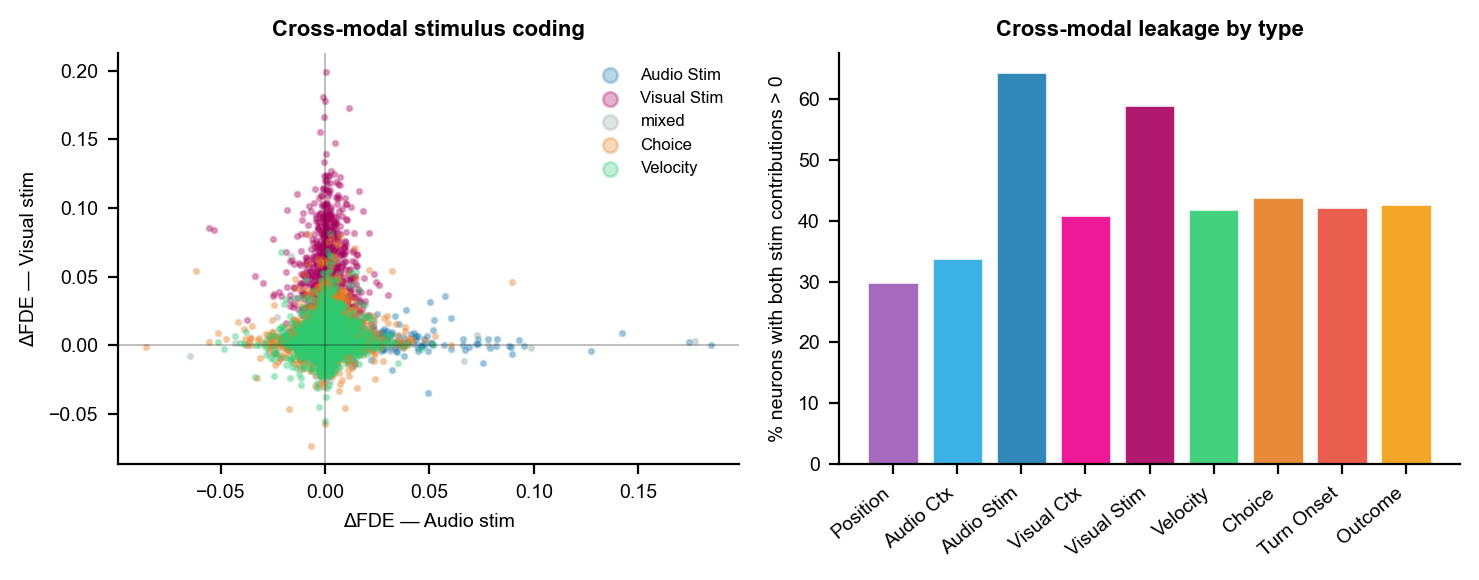

In [16]:
# ── 4a. Audio stim vs Visual stim delta FDE scatter ─────────────────────
if ('delta_fd_audio_stim' not in df_resp.columns or
        'delta_fd_visual_stim' not in df_resp.columns):
    print('Skipping — lesion data required.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.0), dpi=200)

    # Scatter: audio_stim vs visual_stim delta FDE
    ax = axes[0]
    for cls in ['audio_stim', 'visual_stim', 'mixed', 'choice_spatial', 'velocity']:
        if cls not in df_resp['neuron_class'].values: continue
        sub = df_resp[df_resp['neuron_class'] == cls]
        ax.scatter(sub['delta_fd_audio_stim'], sub['delta_fd_visual_stim'],
                   s=3, alpha=0.3, color=CLASS_COLORS.get(cls, 'gray'),
                   label=GROUP_LABELS.get(cls, cls))
    ax.axhline(0, color='k', lw=0.6, alpha=0.3)
    ax.axvline(0, color='k', lw=0.6, alpha=0.3)
    ax.set_xlabel('ΔFDE — Audio stim', fontsize=7)
    ax.set_ylabel('ΔFDE — Visual stim', fontsize=7)
    ax.set_title('Cross-modal stimulus coding', fontsize=8, fontweight='bold')
    ax.legend(fontsize=6, markerscale=3, frameon=False)
    sns.despine(ax=ax)

    # Bar: % with cross-modal contribution (both > 0) per type
    ax = axes[1]
    classes_present = [g for g in M1_GROUPS
                       if g in df_resp['dominant_group'].values]
    both_pos = (
        (df_resp['delta_fd_audio_stim']  > 0) &
        (df_resp['delta_fd_visual_stim'] > 0)
    )
    cross_pct = [
        both_pos.loc[
            df_resp[df_resp['dominant_group'] == g].index
        ].mean() * 100
        for g in classes_present
    ]
    ax.bar(
        range(len(classes_present)), cross_pct,
        color=[GROUP_COLORS.get(g, 'gray') for g in classes_present],
        edgecolor='white', alpha=0.9
    )
    ax.set_xticks(range(len(classes_present)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(g, g) for g in classes_present],
        rotation=40, ha='right', fontsize=7
    )
    ax.set_ylabel('% neurons with both stim contributions > 0', fontsize=7)
    ax.set_title('Cross-modal leakage by type', fontsize=8, fontweight='bold')
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q2_crossmodal_coding.svg', bbox_inches='tight', facecolor='white')
    plt.show()

## Section 5 — Per-Context Lesion Analysis (Future Work)

The proxy analysis above (Sec 2) uses full-model FDE per context as a stand-in for per-context encoding profiles. To directly answer which **predictor group** (kinematics, sensory, choice, etc.) drives each neuron within each context, we need to re-evaluate the lesion models on context-specific test frames.

**What this requires:** Run `run_sessions_ctx_lesion.py` to generate `glm_M1_ctx_lesion_all.pkl` for each session.

**Output of per-context lesion analysis:**
- `delta_frac_dev_per_ctx[group][ctx]` — unique contribution of each group within each context
- This enables direct comparison: does a choice-dominant neuron still have high choice delta_FDE in both Visual and Audio contexts?

**Planned analyses (once data is available):**
1. Heatmap: merged ΔFDE per neuron × context — do the dominant groups shift?
2. Context stability index per group: `cos_sim(delta_fd_visual, delta_fd_audio)` per neuron
3. Neuron reclassification: invariant if dominant group is the same in both contexts
4. Is choice coding more invariant than sensory coding? (key claim for abstract)

In [17]:
# ── Load per-context lesion results (when available) ─────────────────────
# Run run_sessions_ctx_lesion.py first, then reload here.

ctx_lesion_available = []
for mouse_ID, dates in PPC_AVC.items():
    for date in dates:
        path = os.path.join(
            BASE_DATA_PATH, mouse_ID, date,
            'Model_1_results', 'glm_M1_ctx_lesion_ctx_all.pkl'
        )
        if os.path.exists(path):
            ctx_lesion_available.append((mouse_ID, date))

print(f'Per-context lesion results available: {len(ctx_lesion_available)} / '
      f'{sum(len(v) for v in PPC_AVC.values())} sessions')
if ctx_lesion_available:
    print('Sessions with ctx lesion:')
    for m, d in ctx_lesion_available:
        print(f'  {m}/{d}')
else:
    print('\nRun run_sessions_ctx_lesion.py to generate per-context lesion data.')

Per-context lesion results available: 0 / 35 sessions

Run run_sessions_ctx_lesion.py to generate per-context lesion data.
